## INTRODUCTION 
The objective of this assignment is to apply supervised machine learning techniques to predict which passengers survived the tragedy of the sinking of the famous ship of the Titanic

To achieve this we will use Python libraries like pandas to extract the data needed from the data sets given by the assignment .

Throughout the process, we will address several key issues, including the following:

    1)Load type data from the data sets and do a bit of data cleaning to facilitate the use of the algorithm to it 

    2)Explore the data given and try to find any relations between it, making observations and doing analysis of our observations 

    3)Model training and testing with more than one type of algorithm to see the contrast between one and another

    4)Make analysis of which of the analysis that we have done fits the best to our problem and why
    
This brief introduction will guide you through the process as we explain each step 

First step is to import the libraries "pandas and "sklearn" , that we will call as "pd" and "sl" respectively

In [ ]:
import pandas as pd 
import sklearn as sl
import seaborn as sns 
import matplotlib.pyplot as plt


1)Now we load our data given by the statement to two variables 

    1) titanic_train.csv => data 
    2) titanic_test.csv => Tdata 

In [ ]:
data = pd.read_csv('../data/titanic_train.csv')

Tdata = pd.read_csv('../data/titanic_test.csv')


Whe start by analizing the data given to start the cleaning 

In [ ]:
data.shape
data.info()
display(data.head())


<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   pclass    1047 non-null   int64
 1   survived  1047 non-null   int64
 2   name      1047 non-null   str  
 3   sex       1047 non-null   str  
 4   age       1047 non-null   str  
 5   sibsp     1047 non-null   int64
 6   parch     1047 non-null   int64
 7   ticket    1047 non-null   str  
 8   fare      1047 non-null   str  
 9   cabin     1047 non-null   str  
 10  embarked  1047 non-null   str  
 11  boat      1047 non-null   str  
 12  body      1047 non-null   str  
 13  homedest  1047 non-null   str  
dtypes: int64(4), str(10)
memory usage: 114.6 KB


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
0,3,0,"Stoytcheff, Mr. Ilia",male,19,0,0,349205,7.8958,?,S,?,?,?
1,3,0,"Kink, Mr. Vincenz",male,26,2,0,315151,8.6625,?,S,?,?,?
2,3,0,"Sivic, Mr. Husein",male,40,0,0,349251,7.8958,?,S,?,?,?
3,2,1,"Brown, Miss. Edith Eileen",female,15,0,2,29750,39,?,S,14,?,"Cape Town, South Africa / Seattle, WA"
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,?,1,0,17453,89.1042,C92,C,5,?,"Paris, France / New York, NY"


We can do a more in depht analysis by using this comand :

In [ ]:
data.describe(include='all')

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
count,1047.000000,1047.000000,1047,1047,1047,1047.000000,1047.000000,1047,1047,1047,1047,1047,1047,1047
unique,NaN,NaN,1047,2,96,NaN,NaN,797,261,162,4,27,92,322
top,NaN,NaN,"Stoytcheff, Mr. Ilia",male,?,NaN,NaN,CA. 2343,13,?,S,?,?,?
freq,NaN,NaN,1,677,224,NaN,NaN,9,52,814,727,659,956,464
mean,2.309456,0.380134,NaN,NaN,NaN,0.479465,0.387775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.835251,0.485651,NaN,NaN,NaN,1.009187,0.893231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,3.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,3.000000,1.000000,NaN,NaN,NaN,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We clearly see that the features ticket and cabin can be removed due to the large percentage of mising data, and in the data are very unique so it will lead problems for classification methods

2) Now we proceed to find the best ways of cleaning our both data sets 
     We also have to convert into numerical type the features that has numbers in it .

FIRST WE ANALYSE THE TRAIN SET :

    1)In the age column it appears this symbols ? and we have to convert it to number format Nan

    2)In the column body we replace the symbols ? with 0 

    3)In the column boat we replace the symbol ? with 0
AND WE CONVERT EACH COLUMN INTO A NUMERICAL TYPE OF DATA 
    



In [ ]:
# Replace '?' by NaN
data['age'] = data['age'].replace('?', pd.NA)

# convert age into a numerical column
data['age'] = pd.to_numeric(data['age'], errors='coerce')

# Replace the specific symbol (e.g., '?') with 0
data['boat'] = data['boat'].replace('?', 0)

# Convert the 'boat' column to numeric
data['boat'] = pd.to_numeric(data['boat'], errors='coerce')

# Replace the specific symbol (e.g., '?') with 0
data['body'] = data['body'].replace('?', 0)

# Convert the 'boat' column to numeric
data['body'] = pd.to_numeric(data['body'], errors='coerce')

# Convert the 'fare' column to float64
data['fare'] = pd.to_numeric(data['fare'], errors='coerce')

display(data)
data.info()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
0,3,0,"Stoytcheff, Mr. Ilia",male,19.0,0,0,349205,7.8958,?,S,0.0,0,?
1,3,0,"Kink, Mr. Vincenz",male,26.0,2,0,315151,8.6625,?,S,0.0,0,?
2,3,0,"Sivic, Mr. Husein",male,40.0,0,0,349251,7.8958,?,S,0.0,0,?
3,2,1,"Brown, Miss. Edith Eileen",female,15.0,0,2,29750,39.0000,?,S,14.0,0,"Cape Town, South Africa / Seattle, WA"
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,NaN,1,0,17453,89.1042,C92,C,5.0,0,"Paris, France / New York, NY"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,1,1,"Frolicher-Stehli, Mr. Maxmillian",male,60.0,1,1,13567,79.2000,B41,C,5.0,0,"Zurich, Switzerland"
1043,2,1,"Shelley, Mrs. William (Imanita Parrish Hall)",female,25.0,0,1,230433,26.0000,?,S,12.0,0,"Deer Lodge, MT"
1044,3,0,"Plotcharsky, Mr. Vasil",male,NaN,0,0,349227,7.8958,?,S,0.0,0,?
1045,3,0,"Canavan, Mr. Patrick",male,21.0,0,0,364858,7.7500,?,Q,0.0,0,"Ireland Philadelphia, PA"


<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1047 non-null   int64  
 1   survived  1047 non-null   int64  
 2   name      1047 non-null   str    
 3   sex       1047 non-null   str    
 4   age       823 non-null    float64
 5   sibsp     1047 non-null   int64  
 6   parch     1047 non-null   int64  
 7   ticket    1047 non-null   str    
 8   fare      1046 non-null   float64
 9   cabin     1047 non-null   str    
 10  embarked  1047 non-null   str    
 11  boat      980 non-null    float64
 12  body      1047 non-null   int64  
 13  homedest  1047 non-null   str    
dtypes: float64(3), int64(5), str(6)
memory usage: 114.6 KB


We can we that we have missing data in:
    1) Age
    2) Fare
    3) Boat

We complete the data of AGE with the median of each feature needed 

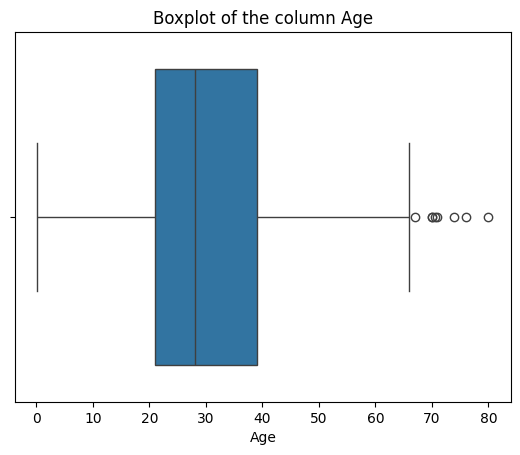

In [ ]:
sns.boxplot(x=data['age'].dropna())  # Eliminar valores no definidos
plt.title('Boxplot of the column Age')
plt.xlabel('Age')
plt.show()

Its reasonable to use the mean at the time of looking to the boxplot and not seeing many outliers 

In [ ]:
data['age'] = data['age'].fillna(data['age'].mean())
data['embarked']=data['embarked'].fillna('S')
display(data)
data.describe(include='all')

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
0,3,0,"Stoytcheff, Mr. Ilia",male,19.000000,0,0,349205,7.8958,?,S,0.0,0,?
1,3,0,"Kink, Mr. Vincenz",male,26.000000,2,0,315151,8.6625,?,S,0.0,0,?
2,3,0,"Sivic, Mr. Husein",male,40.000000,0,0,349251,7.8958,?,S,0.0,0,?
3,2,1,"Brown, Miss. Edith Eileen",female,15.000000,0,2,29750,39.0000,?,S,14.0,0,"Cape Town, South Africa / Seattle, WA"
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,29.646719,1,0,17453,89.1042,C92,C,5.0,0,"Paris, France / New York, NY"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,1,1,"Frolicher-Stehli, Mr. Maxmillian",male,60.000000,1,1,13567,79.2000,B41,C,5.0,0,"Zurich, Switzerland"
1043,2,1,"Shelley, Mrs. William (Imanita Parrish Hall)",female,25.000000,0,1,230433,26.0000,?,S,12.0,0,"Deer Lodge, MT"
1044,3,0,"Plotcharsky, Mr. Vasil",male,29.646719,0,0,349227,7.8958,?,S,0.0,0,?
1045,3,0,"Canavan, Mr. Patrick",male,21.000000,0,0,364858,7.7500,?,Q,0.0,0,"Ireland Philadelphia, PA"


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
count,1047.000000,1047.000000,1047,1047,1047.000000,1047.000000,1047.000000,1047,1046.000000,1047,1047,980.000000,1047.000000,1047
unique,NaN,NaN,1047,2,NaN,NaN,NaN,797,NaN,162,4,NaN,NaN,322
top,NaN,NaN,"Stoytcheff, Mr. Ilia",male,NaN,NaN,NaN,CA. 2343,NaN,?,S,NaN,NaN,?
freq,NaN,NaN,1,677,NaN,NaN,NaN,9,NaN,814,727,NaN,NaN,464
mean,2.309456,0.380134,NaN,NaN,29.646719,0.479465,0.387775,NaN,32.667180,NaN,NaN,3.064286,14.250239,NaN
std,0.835251,0.485651,NaN,NaN,12.959606,1.009187,0.893231,NaN,51.582398,NaN,NaN,5.056065,54.303239,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,0.000000,0.000000,NaN
25%,2.000000,0.000000,NaN,NaN,22.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,0.000000,0.000000,NaN
50%,3.000000,0.000000,NaN,NaN,29.646719,0.000000,0.000000,NaN,13.858300,NaN,NaN,0.000000,0.000000,NaN
75%,3.000000,1.000000,NaN,NaN,35.000000,1.000000,0.000000,NaN,30.695800,NaN,NaN,5.000000,0.000000,NaN


Now we complete the feature fare but first we nneed to see how its data is labeled 

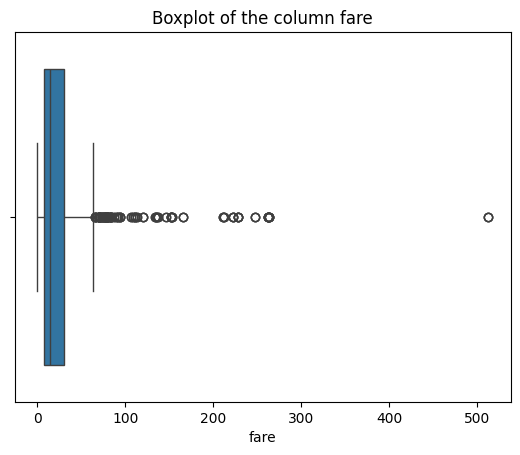

In [ ]:
sns.boxplot(x=data['fare'].dropna())  # Eliminar valores no definidos
plt.title('Boxplot of the column fare')
plt.xlabel('fare')
plt.show()

We must apply the maedian for fare because there are so many outliers that would affect if type apply the mean instead 

In [ ]:
data['fare'] = data['fare'].fillna(data['fare'].median())

Then we got left only the boat columns with the missing values that we are gonna substitute with 0 the '?' and with 1 other value that appears on it

(`boat` is later **dropped before modelling** because it leaks the target; see the note below.)

In [ ]:
# Convert the 'boat' column: set to 0 if the value is 0, otherwise set to 1
data['boat'] = data['boat'].apply(lambda x: 0 if x == 0 else 1)
display(data)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest
0,3,0,"Stoytcheff, Mr. Ilia",male,19.000000,0,0,349205,7.8958,?,S,0,0,?
1,3,0,"Kink, Mr. Vincenz",male,26.000000,2,0,315151,8.6625,?,S,0,0,?
2,3,0,"Sivic, Mr. Husein",male,40.000000,0,0,349251,7.8958,?,S,0,0,?
3,2,1,"Brown, Miss. Edith Eileen",female,15.000000,0,2,29750,39.0000,?,S,1,0,"Cape Town, South Africa / Seattle, WA"
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,29.646719,1,0,17453,89.1042,C92,C,1,0,"Paris, France / New York, NY"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,1,1,"Frolicher-Stehli, Mr. Maxmillian",male,60.000000,1,1,13567,79.2000,B41,C,1,0,"Zurich, Switzerland"
1043,2,1,"Shelley, Mrs. William (Imanita Parrish Hall)",female,25.000000,0,1,230433,26.0000,?,S,1,0,"Deer Lodge, MT"
1044,3,0,"Plotcharsky, Mr. Vasil",male,29.646719,0,0,349227,7.8958,?,S,0,0,?
1045,3,0,"Canavan, Mr. Patrick",male,21.000000,0,0,364858,7.7500,?,Q,0,0,"Ireland Philadelphia, PA"


we check if there is any othe feature incomplete 

In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1047 non-null   int64  
 1   survived  1047 non-null   int64  
 2   name      1047 non-null   str    
 3   sex       1047 non-null   str    
 4   age       1047 non-null   float64
 5   sibsp     1047 non-null   int64  
 6   parch     1047 non-null   int64  
 7   ticket    1047 non-null   str    
 8   fare      1047 non-null   float64
 9   cabin     1047 non-null   str    
 10  embarked  1047 non-null   str    
 11  boat      1047 non-null   int64  
 12  body      1047 non-null   int64  
 13  homedest  1047 non-null   str    
dtypes: float64(2), int64(6), str(6)
memory usage: 114.6 KB


## Once we have done this we have to analyse the features to find out which has more relevance for our prediction 

In [ ]:
data['sex'].value_counts()

sex
male      677
female    370
Name: count, dtype: int64

,survived
sex,
female,0.727027
male,0.190547


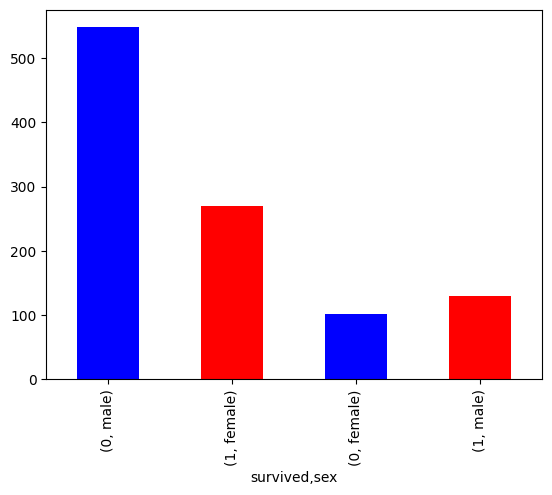

In [ ]:
data[['survived', 'sex']].value_counts(sort=False).plot(kind='bar', color=['b', 'r'])

data[['sex','survived']].groupby('sex').mean()

We can see that the feature sex is relevant for our model because we see that more female survived than men 

In [ ]:
import pandas as pd

# Crear columnas de one hot encoding para la columna 'sex' sin eliminar la original
data = pd.concat([data, pd.get_dummies(data['sex'], dtype=int)], axis=1)


In [ ]:
display(data)
data.info()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest,female,male
0,3,0,"Stoytcheff, Mr. Ilia",male,19.000000,0,0,349205,7.8958,?,S,0,0,?,0,1
1,3,0,"Kink, Mr. Vincenz",male,26.000000,2,0,315151,8.6625,?,S,0,0,?,0,1
2,3,0,"Sivic, Mr. Husein",male,40.000000,0,0,349251,7.8958,?,S,0,0,?,0,1
3,2,1,"Brown, Miss. Edith Eileen",female,15.000000,0,2,29750,39.0000,?,S,1,0,"Cape Town, South Africa / Seattle, WA",1,0
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,29.646719,1,0,17453,89.1042,C92,C,1,0,"Paris, France / New York, NY",1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,1,1,"Frolicher-Stehli, Mr. Maxmillian",male,60.000000,1,1,13567,79.2000,B41,C,1,0,"Zurich, Switzerland",0,1
1043,2,1,"Shelley, Mrs. William (Imanita Parrish Hall)",female,25.000000,0,1,230433,26.0000,?,S,1,0,"Deer Lodge, MT",1,0
1044,3,0,"Plotcharsky, Mr. Vasil",male,29.646719,0,0,349227,7.8958,?,S,0,0,?,0,1
1045,3,0,"Canavan, Mr. Patrick",male,21.000000,0,0,364858,7.7500,?,Q,0,0,"Ireland Philadelphia, PA",0,1


<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1047 non-null   int64  
 1   survived  1047 non-null   int64  
 2   name      1047 non-null   str    
 3   sex       1047 non-null   str    
 4   age       1047 non-null   float64
 5   sibsp     1047 non-null   int64  
 6   parch     1047 non-null   int64  
 7   ticket    1047 non-null   str    
 8   fare      1047 non-null   float64
 9   cabin     1047 non-null   str    
 10  embarked  1047 non-null   str    
 11  boat      1047 non-null   int64  
 12  body      1047 non-null   int64  
 13  homedest  1047 non-null   str    
 14  female    1047 non-null   int64  
 15  male      1047 non-null   int64  
dtypes: float64(2), int64(8), str(6)
memory usage: 131.0 KB


## PCLASS

In [ ]:


data[['pclass','survived']].groupby('pclass').mean()


,survived
pclass,
1,0.624506
2,0.433180
3,0.253033


Now we add a binary feature for the sex to simplify the work and start working with numbers

<Axes: xlabel='survived,pclass'>

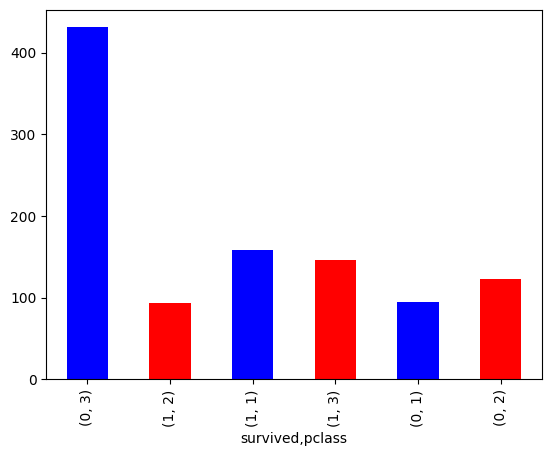

In [ ]:
data[['survived', 'pclass']].value_counts(sort=False).plot(kind='bar', color=['b', 'r'])

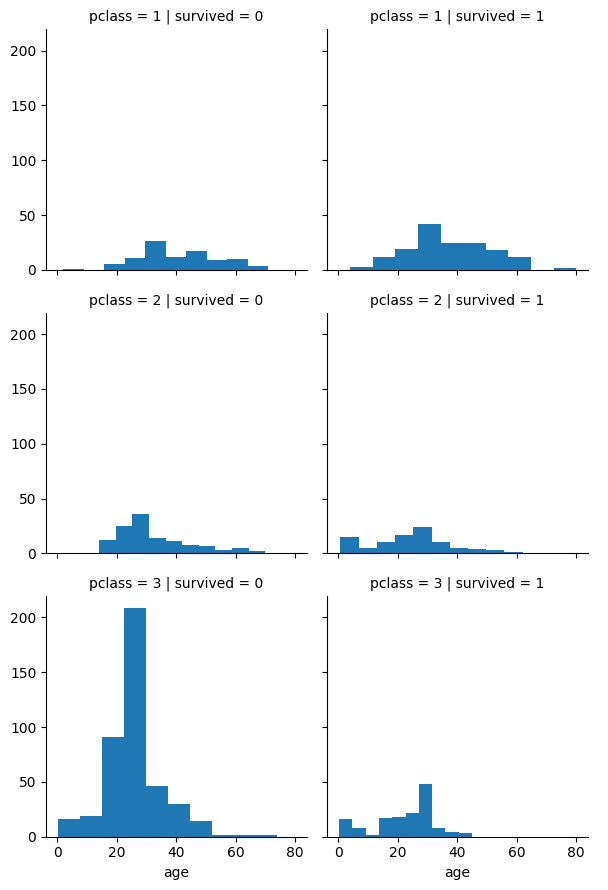

In [ ]:
grid=sns.FacetGrid(data,col='survived',row='pclass')
grid.map(plt.hist,'age',bins=10)
grid.add_legend()

We see that the feature Pclass also is very relevant for our model, third class died much more than 2 and than 1 

## SIBSP
    Being the max of 8 in our data 

In [ ]:
data[['sibsp','survived']].groupby('sibsp').mean().sort_values(by='survived',ascending=False)

,survived
sibsp,
1,0.503968
2,0.457143
0,0.344924
3,0.266667
4,0.187500
5,0.000000
8,0.000000


<Axes: xlabel='survived,sibsp'>

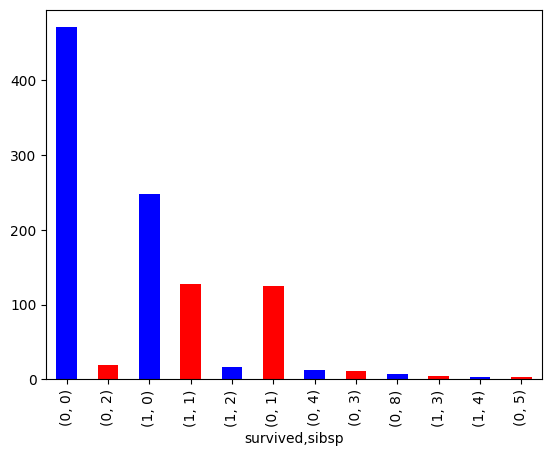

In [ ]:
data[['survived', 'sibsp']].value_counts(sort=False).plot(kind='bar', color=['b', 'r'])

We see that the graphs are very similar in the values so maybe it will confuse our algorithm so we decide to get rid of this feature 

## PARCH 

In [ ]:
data[['parch','survived']].groupby('parch').mean().sort_values(by='survived',ascending=False)

,survived
parch,
1,0.579710
3,0.571429
2,0.500000
0,0.336239
5,0.200000
4,0.166667
6,0.000000
9,0.000000


<Axes: xlabel='survived,parch'>

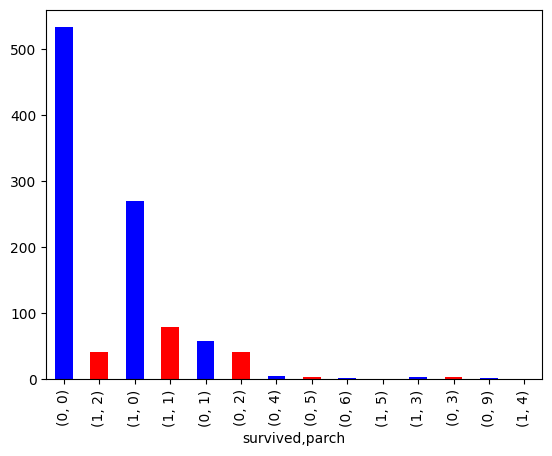

In [ ]:
data[['survived', 'parch']].value_counts(sort=False).plot(kind='bar', color=['b', 'r'])

By the same reason as we remove the sibsp feature we can remove this one ass well 

## AGE

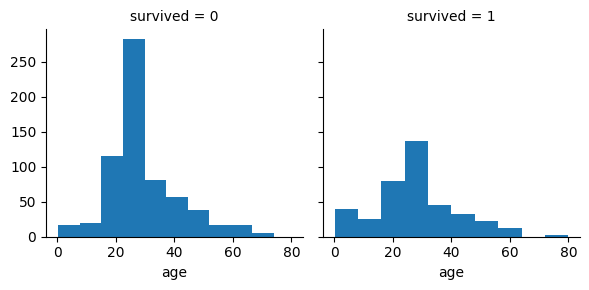

In [ ]:
hist_age = sns.FacetGrid(data,col='survived')
hist_age.map(plt.hist,'age',bins=10)

We noticed that for young ages were more probable to survive , but if we see the most survived age is more or less the age that most people didn't survived, so it would not be very useful this feature 

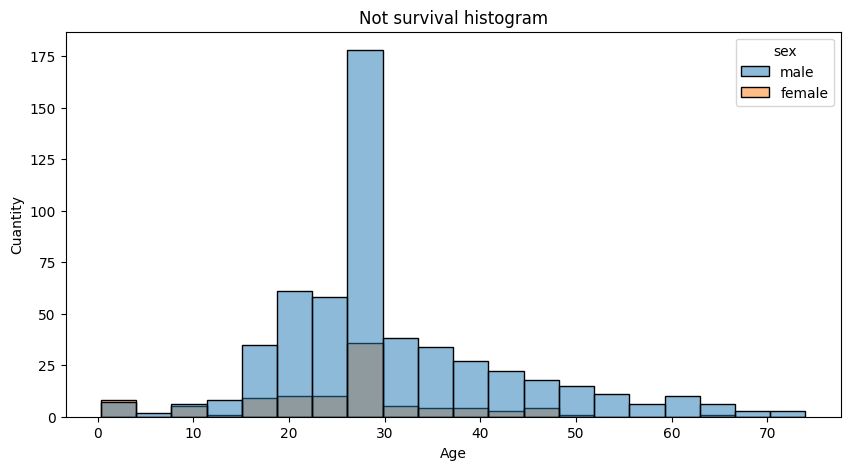

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data=data[data['survived'] == 0],x='age',hue='sex',bins = 20,label='Did not survive ')
plt.xlabel('Age')
plt.ylabel('Cuantity')
plt.title('Not survival histogram')
plt.show()

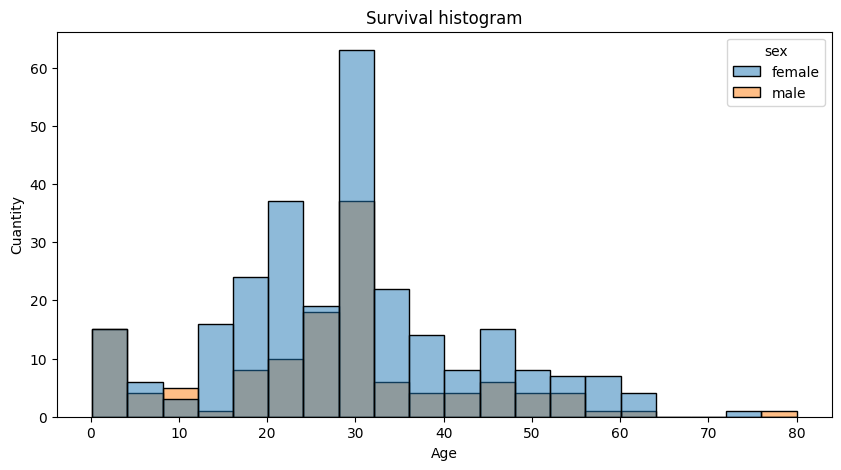

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data=data[data['survived'] == 1],x='age',hue='sex',bins = 20,label='Did survive ')
plt.xlabel('Age')
plt.ylabel('Cuantity')
plt.title('Survival histogram')
plt.show()

We can see the relation of age and sex , and we see agian the importance of the sex 

With the graphs we see that we could use age intervals to make thsi feature more useful to our model 
Also is easier for the model with four type of data in a columns rather than for the ages 

In [ ]:
# Apply the age ranges specified in your message to both the training and test datasets
for dataset in [data]:  # Replace `[data]` with `[train_data, test_data]` if you have separate datasets
    dataset.loc[dataset['age'] <= 16, 'age'] = 0
    dataset.loc[(dataset['age'] > 16) & (dataset['age'] <= 26), 'age'] = 1
    dataset.loc[(dataset['age'] > 26) & (dataset['age'] <= 36), 'age'] = 2
    dataset.loc[(dataset['age'] > 36) & (dataset['age'] <= 62), 'age'] = 3
    dataset.loc[dataset['age'] > 62, 'age'] = 4

## FARE 
To analyse this featute fristly we have to convert it to a numerical number, that originaly is given in a object type 

In [ ]:


# Check the data type of the column to confirm the conversion
print(data['fare'].dtype)

float64


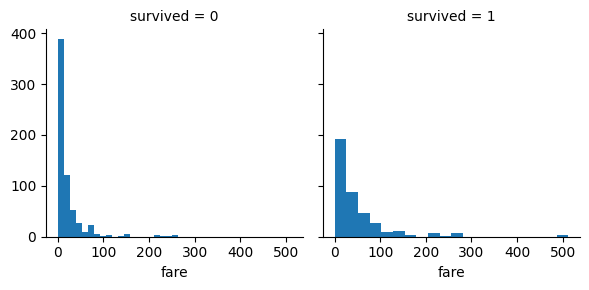

In [ ]:
hist_age = sns.FacetGrid(data,col='survived')
hist_age.map(plt.hist,'fare',bins=20)

We can se that with a low value of fare its more probable to nor survived but with a large fare is more porbable that you will survive , this feature is also correlated to the one about the classes being a high class a more fare it has , anf low clasess less fare .

Highest Fare: 512.3292
Lowest Fare: 0.0
32.649215472779375


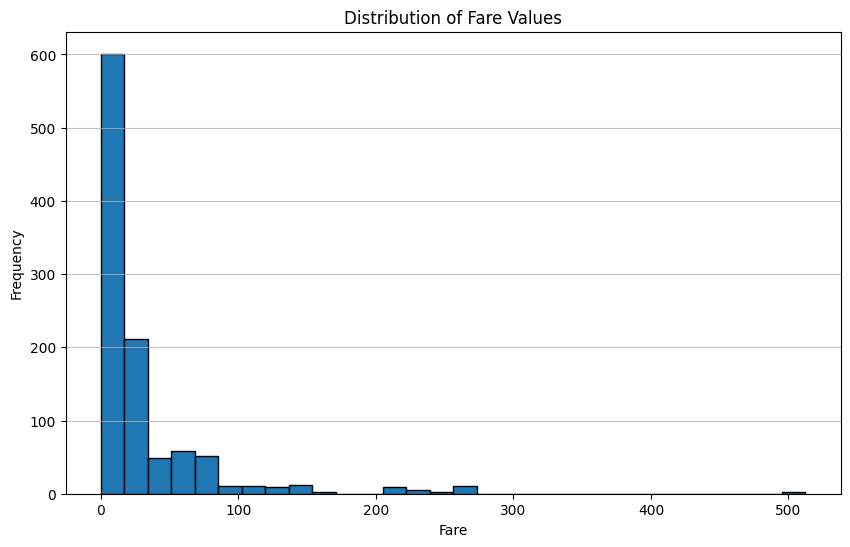

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming your DataFrame is named 'data'
# Replace 'data.csv' with your actual file name if needed
# data = pd.read_csv('data.csv')  # Uncomment this if you need to read from a CSV file

# 1. Calculate the highest and lowest fare
highest_fare = data['fare'].max()
lowest_fare = data['fare'].min()

print(f'Highest Fare: {highest_fare}')
print(f'Lowest Fare: {lowest_fare}')
print(data['fare'].mean())

# 2. Create a histogram to visualize the fare values
plt.figure(figsize=(10, 6))
plt.hist(data['fare'].dropna(), bins=30, edgecolor='black')  # You can adjust the number of bins
plt.title('Distribution of Fare Values')
plt.xlabel('Fare')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

We do feature ingeniering to make amore simple feature of fare by dividing it into intervals to have less distinct numbers in the column and so make a simpler model for the algorithnm

In [ ]:
# Apply the age ranges specified in your message to both the training and test datasets
for dataset in [data]:  # Replace `[data]` with `[train_data, test_data]` if you have separate datasets
    dataset.loc[dataset['fare'] <= 10, 'fare'] = 0
    dataset.loc[(dataset['fare'] > 10) & (dataset['fare'] <= 30), 'fare'] = 1
    dataset.loc[(dataset['fare'] > 30) & (dataset['fare'] <= 100), 'fare'] = 2
    dataset.loc[(dataset['fare'] > 100) & (dataset['fare'] <= 250), 'fare'] = 3
    dataset.loc[dataset['fare'] > 250, 'fare'] = 4


In [ ]:
display(data)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest,female,male
0,3,0,"Stoytcheff, Mr. Ilia",male,1.0,0,0,349205,0.0,?,S,0,0,?,0,1
1,3,0,"Kink, Mr. Vincenz",male,1.0,2,0,315151,0.0,?,S,0,0,?,0,1
2,3,0,"Sivic, Mr. Husein",male,3.0,0,0,349251,0.0,?,S,0,0,?,0,1
3,2,1,"Brown, Miss. Edith Eileen",female,0.0,0,2,29750,2.0,?,S,1,0,"Cape Town, South Africa / Seattle, WA",1,0
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,2.0,1,0,17453,2.0,C92,C,1,0,"Paris, France / New York, NY",1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,1,1,"Frolicher-Stehli, Mr. Maxmillian",male,3.0,1,1,13567,2.0,B41,C,1,0,"Zurich, Switzerland",0,1
1043,2,1,"Shelley, Mrs. William (Imanita Parrish Hall)",female,1.0,0,1,230433,1.0,?,S,1,0,"Deer Lodge, MT",1,0
1044,3,0,"Plotcharsky, Mr. Vasil",male,2.0,0,0,349227,0.0,?,S,0,0,?,0,1
1045,3,0,"Canavan, Mr. Patrick",male,1.0,0,0,364858,0.0,?,Q,0,0,"Ireland Philadelphia, PA",0,1


## DATA CLEANING 

After a quick look through all the titanic tragedy history we can now say which features are important four our prediction of survival:

    1)The name feature is useless in this type of machine learning assignment 

    2)The ticket number is correlated to class by because they share the first number so with the Pclass is sufficient for our model 

    3)The number of cabin is similar to the ticket number and we apply the same logic 

    4)Homedest is a feature that is defined as an object and don't provide us any relevant information por our prediction 

    5)Body feature could be help full if there is data it means that the person died but here is more than a 90% of missing data so it better to remove it 

    6) **boat** records the lifeboat a passenger boarded, which is only known *because* the passenger survived. It is target leakage, so it is excluded from all models

    7) embarked : We tried with one hot encoding of embarked and give ass lower or the same precision 



In [ ]:
# Total number of rows
total_rows = 1047

# Count zeros in the 'boat' and 'body' columns
total_zero_boat = (data['boat'] == 0).sum()
total_zero_body = (data['body'] == 0).sum()

# Calculate percentages
percentage_zero_boat = (total_zero_boat / total_rows) * 100
percentage_zero_body = (total_zero_body / total_rows) * 100

# Display results
print(f'Boat - Zeros: {total_zero_boat}, Percentage: {percentage_zero_boat:.2f}%')
print(f'Body - Zeros: {total_zero_body}, Percentage: {percentage_zero_body:.2f}%')
display(data)

Boat - Zeros: 659, Percentage: 62.94%
Body - Zeros: 956, Percentage: 91.31%


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,homedest,female,male
0,3,0,"Stoytcheff, Mr. Ilia",male,1.0,0,0,349205,0.0,?,S,0,0,?,0,1
1,3,0,"Kink, Mr. Vincenz",male,1.0,2,0,315151,0.0,?,S,0,0,?,0,1
2,3,0,"Sivic, Mr. Husein",male,3.0,0,0,349251,0.0,?,S,0,0,?,0,1
3,2,1,"Brown, Miss. Edith Eileen",female,0.0,0,2,29750,2.0,?,S,1,0,"Cape Town, South Africa / Seattle, WA",1,0
4,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,2.0,1,0,17453,2.0,C92,C,1,0,"Paris, France / New York, NY",1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1042,1,1,"Frolicher-Stehli, Mr. Maxmillian",male,3.0,1,1,13567,2.0,B41,C,1,0,"Zurich, Switzerland",0,1
1043,2,1,"Shelley, Mrs. William (Imanita Parrish Hall)",female,1.0,0,1,230433,1.0,?,S,1,0,"Deer Lodge, MT",1,0
1044,3,0,"Plotcharsky, Mr. Vasil",male,2.0,0,0,349227,0.0,?,S,0,0,?,0,1
1045,3,0,"Canavan, Mr. Patrick",male,1.0,0,0,364858,0.0,?,Q,0,0,"Ireland Philadelphia, PA",0,1


**Data-leakage note.** An earlier version of this notebook kept `boat` as a predictor. That variable records the lifeboat a passenger boarded, i.e. information that only exists *because* the passenger survived, so it leaks the target and inflates accuracy to ~96-98 %. It is excluded from every model below, so all metrics reported here are leakage-free.

In [ ]:
data.drop(['name','ticket','cabin','embarked','body','boat','homedest','sex'],axis = 1,inplace=True)
data.info()
display(data)

<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1047 non-null   int64  
 1   survived  1047 non-null   int64  
 2   age       1047 non-null   float64
 3   sibsp     1047 non-null   int64  
 4   parch     1047 non-null   int64  
 5   fare      1047 non-null   float64
 6   female    1047 non-null   int64  
 7   male      1047 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 65.6 KB


,pclass,survived,age,sibsp,parch,fare,female,male
0,3,0,1.0,0,0,0.0,0,1
1,3,0,1.0,2,0,0.0,0,1
2,3,0,3.0,0,0,0.0,0,1
3,2,1,0.0,0,2,2.0,1,0
4,1,1,2.0,1,0,2.0,1,0
...,...,...,...,...,...,...,...,...
1042,1,1,3.0,1,1,2.0,0,1
1043,2,1,1.0,0,1,1.0,1,0
1044,3,0,2.0,0,0,0.0,0,1
1045,3,0,1.0,0,0,0.0,0,1


In [ ]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1047 non-null   int64  
 1   survived  1047 non-null   int64  
 2   age       1047 non-null   float64
 3   sibsp     1047 non-null   int64  
 4   parch     1047 non-null   int64  
 5   fare      1047 non-null   float64
 6   female    1047 non-null   int64  
 7   male      1047 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 65.6 KB


Before finishing the cleaning ot our data set we can see the correlation between the features that we have 

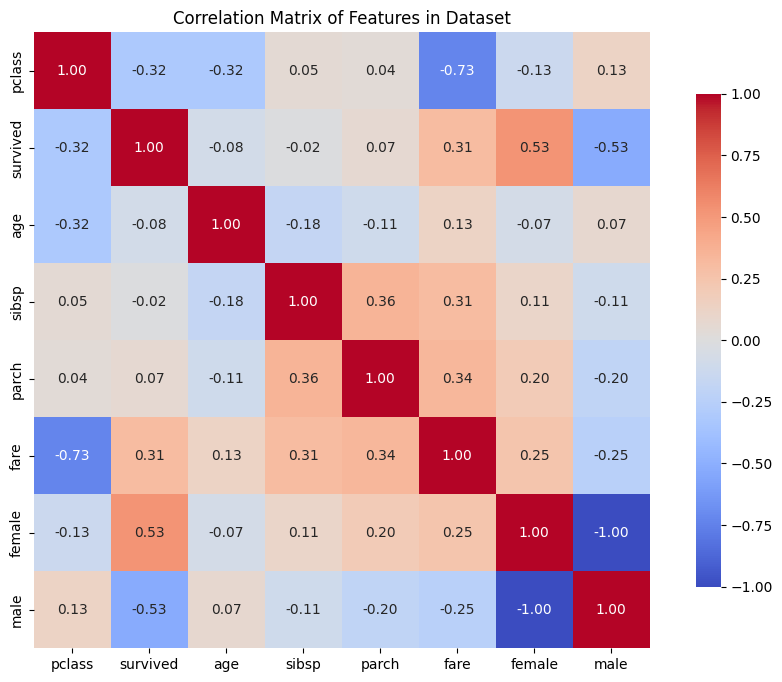

,pclass,survived,age,sibsp,parch,fare,female,male
0,3,0,1.0,0,0,0.0,0,1
1,3,0,1.0,2,0,0.0,0,1
2,3,0,3.0,0,0,0.0,0,1
3,2,1,0.0,0,2,2.0,1,0
4,1,1,2.0,1,0,2.0,1,0
...,...,...,...,...,...,...,...,...
1042,1,1,3.0,1,1,2.0,0,1
1043,2,1,1.0,0,1,1.0,1,0
1044,3,0,2.0,0,0,0.0,0,1
1045,3,0,1.0,0,0,0.0,0,1


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the correlation matrix
correlation_matrix = data.corr()

# Set up the matplotlib figure
plt.figure(figsize=(12, 8))

# Create a heatmap for the correlation matrix
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})

# Set the title of the heatmap
plt.title('Correlation Matrix of Features in Dataset')
plt.show()
display(data)

We can see that the feature sibsp is no correlated this out feature onjetive to predict , so thsi feature don't help us 

In [ ]:
data.drop(['sibsp','parch'],axis = 1,inplace=True)
display(data)
data.info()

,pclass,survived,age,fare,female,male
0,3,0,1.0,0.0,0,1
1,3,0,1.0,0.0,0,1
2,3,0,3.0,0.0,0,1
3,2,1,0.0,2.0,1,0
4,1,1,2.0,2.0,1,0
...,...,...,...,...,...,...
1042,1,1,3.0,2.0,0,1
1043,2,1,1.0,1.0,1,0
1044,3,0,2.0,0.0,0,1
1045,3,0,1.0,0.0,0,1


<class 'pandas.DataFrame'>
RangeIndex: 1047 entries, 0 to 1046
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1047 non-null   int64  
 1   survived  1047 non-null   int64  
 2   age       1047 non-null   float64
 3   fare      1047 non-null   float64
 4   female    1047 non-null   int64  
 5   male      1047 non-null   int64  
dtypes: float64(2), int64(4)
memory usage: 49.2 KB


## IMPORTANCE OF THE FEATURES 

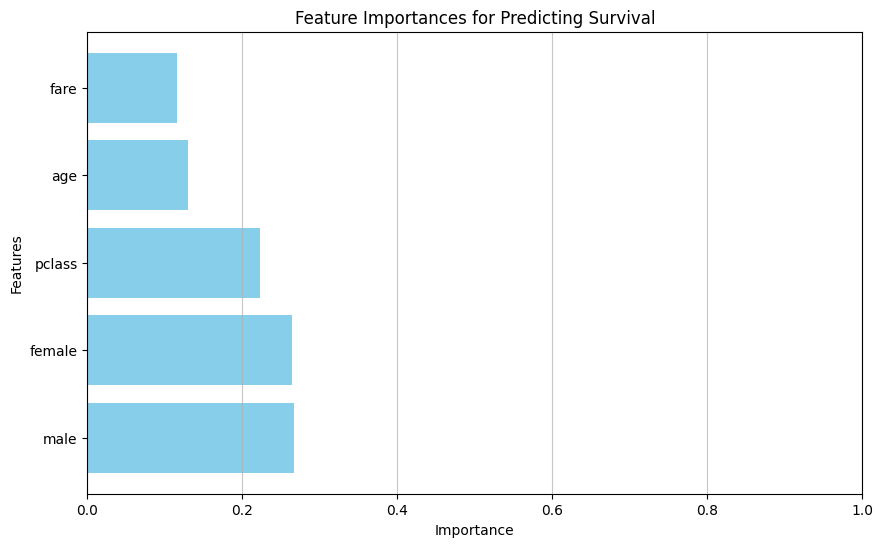

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Assuming your DataFrame is named 'data'
# Split your data into features (X) and target (y)
features = ['pclass', 'age', 'fare', 'female', 'male']
X = data[features]
y = data['survived']

# Handle missing values (if any) - here we fill with the mean or drop, depending on your needs
X['age'].fillna(X['age'].mean(), inplace=True)  # Example for age, adjust as necessary
X['fare'].fillna(X['fare'].mean(), inplace=True)  # Example for fare

# Convert categorical variables if necessary (e.g., one-hot encoding for 'boat' if needed)
# For example: X = pd.get_dummies(X, columns=['boat'], drop_first=True)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Fit the Random Forest Model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Step 3: Get Feature Importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Create a DataFrame for better visualization
feature_importance_df = pd.DataFrame({
    'Feature': np.array(features)[indices],
    'Importance': importances[indices]
})

# Plotting the feature importances
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
plt.title('Feature Importances for Predicting Survival')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.7)
plt.show()

## TEST DATA SET CLEANING 
We have to clean the test data set the same way we did for the train data set in order to hace the same features and value to have a more accurate prediction 

In [ ]:
#Remove the useless features 
# Tdata.drop(['name','ticket','cabin','embarked','boat','body','homedest'],axis = 1,inplace=True)



# # Replace '?' by NaN
Tdata['age'] = Tdata['age'].replace('?', pd.NA)

# # convert age into a numerical column
Tdata['age'] = pd.to_numeric(Tdata['age'], errors='coerce')


# # we work with the missing values in the age column
Tdata['age'] = Tdata['age'].fillna(Tdata['age'].mean())

# Apply the age ranges specified in your message to both the training and test datasets
for dataset in [Tdata]:  # Replace `[data]` with `[train_data, test_data]` if you have separate datasets
    dataset.loc[dataset['age'] <= 16, 'age'] = 0
    dataset.loc[(dataset['age'] > 16) & (dataset['age'] <= 26), 'age'] = 1
    dataset.loc[(dataset['age'] > 26) & (dataset['age'] <= 36), 'age'] = 2
    dataset.loc[(dataset['age'] > 36) & (dataset['age'] <= 62), 'age'] = 3
    dataset.loc[dataset['age'] > 62, 'age'] = 4

# # we do one hot encoding to the sex column 
import pandas as pd

# Crear columnas de one hot encoding para la columna 'sex' sin eliminar la original
Tdata = pd.concat([Tdata, pd.get_dummies(Tdata['sex'], dtype=int)], axis=1)


# Replace the specific symbol (e.g., '?') with 0
Tdata['boat'] = Tdata['boat'].replace('?', 0)

# Convert the 'boat' column to numeric
Tdata['boat'] = pd.to_numeric(Tdata['boat'], errors='coerce')

# Convert the 'boat' column: set to 0 if the value is 0, otherwise set to 1
Tdata['boat'] = Tdata['boat'].apply(lambda x: 0 if x == 0 else 1)




# Apply the age ranges specified in your message to both the training and test datasets
for dataset in [Tdata]:  # Replace `[data]` with `[train_data, test_data]` if you have separate datasets
    dataset.loc[dataset['fare'] <= 10, 'fare'] = 0
    dataset.loc[(dataset['fare'] > 10) & (dataset['fare'] <= 30), 'fare'] = 1
    dataset.loc[(dataset['fare'] > 30) & (dataset['fare'] <= 100), 'fare'] = 2
    dataset.loc[(dataset['fare'] > 100) & (dataset['fare'] <= 250), 'fare'] = 3
    dataset.loc[dataset['fare'] > 250, 'fare'] = 4


# we remove the same features that for the test data 

Tdata.drop(['name','ticket','cabin','embarked','body','homedest','sibsp','parch','sex'],axis = 1,inplace=True)





display(Tdata)
Tdata.info()

# 'boat' is a post-outcome variable (data leakage): never used as a predictor
Tdata.drop(columns=['boat'], errors='ignore', inplace=True)


,pclass,survived,age,fare,boat,female,male
0,3,0,3.0,0.0,0,0,1
1,1,0,3.0,2.0,0,0,1
2,2,0,1.0,1.0,0,0,1
3,3,0,2.0,1.0,0,0,1
4,3,0,2.0,0.0,0,0,1
...,...,...,...,...,...,...,...
257,2,1,2.0,1.0,1,1,0
258,3,0,2.0,1.0,0,0,1
259,1,0,2.0,2.0,0,0,1
260,3,0,1.0,1.0,0,0,1


<class 'pandas.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    262 non-null    int64  
 1   survived  262 non-null    int64  
 2   age       262 non-null    float64
 3   fare      262 non-null    float64
 4   boat      262 non-null    int64  
 5   female    262 non-null    int64  
 6   male      262 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 14.5 KB


In [ ]:
# Exportar los datasets limpios a CSV
data.to_csv('../data/processed/titanic_train_clean.csv', index=False)
Tdata.to_csv('../data/processed/titanic_test_clean.csv', index=False)

 ## TRAIN THE MODEL 

### Random Forest

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve, validation_curve
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score



# Define the feature set and the target variable for the training dataset
X_train = data.drop('survived', axis=1)  # Drop the target column 'survived'
y_train = data['survived']  # The target column

# Define the hyperparameters for Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,       # Number of trees in the forest
    max_depth=20,           # Maximum depth of the tree
    min_samples_split=5,    # Minimum number of samples required to split an internal node
    min_samples_leaf=2,     # Minimum number of samples required to be at a leaf node
    bootstrap=True,         # Whether bootstrap samples are used when building trees
    random_state=42
)

# Train the Random Forest model on the training data
rf_model.fit(X_train, y_train)

# Predict the 'survived' column in the test dataset (Tdata)
X_test = Tdata.drop('survived', axis=1, errors='ignore')  # Drop 'survived' if present in Tdata
y_pred = rf_model.predict(X_test)

#Evaluate accuracy if you have the true 'survived' column in Tdata
y_test = Tdata['survived']
accuracy = accuracy_score(y_test, y_pred)
print(f'Model accuracy: {accuracy:.2f}')

Model accuracy: 0.78


#### Cross Validation Random Forest

We applied cross-validation to the Random Forest algorithm to see how it performs with new data.

In [ ]:
# Perform cross-validation
# 'cv=5' indicates 5 folds; you can adjust this as needed
# 'scoring' defines the evaluation metric, here we use 'accuracy'
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='accuracy')

# Display the results
print(f'Scores per fold: {cv_scores}')
print(f'Average accuracy: {cv_scores.mean():.2f}')

Scores per fold: [0.75238095 0.76666667 0.81818182 0.77990431 0.80382775]
Average accuracy: 0.78


Now we create:
- Confusion matrix to see how the algorithm predicts each label. 

- Precision, recall, and F1 score: these metrics return the percentage of correct predictions among all those predicted as positive, the percentage of correct predictions among the actual positives, and the harmonic mean between precision and recall, respectively.

- Learning curve to observe how the algorithm behaves with different sample sizes, and we review the results using both training data and validation data while applying cross-validation.
 
- The validation curve functions similarly to the learning curve but focuses on a hyperparameter instead of the sample size; in this case, we use max depth, as it is one of the most significant hyperparameters.

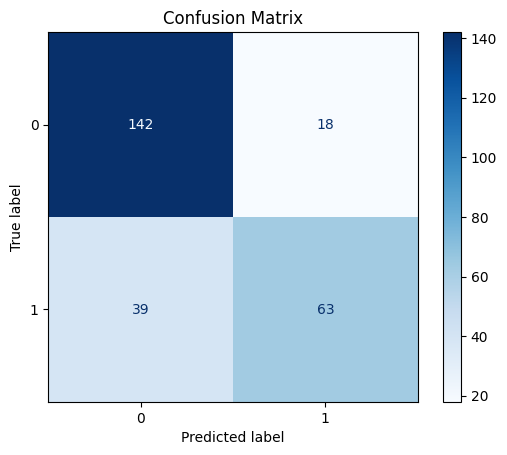


Custom Classification Report:
   Precision    Recall  F1 Score
0   0.784530  0.887500  0.832845
1   0.777778  0.617647  0.688525


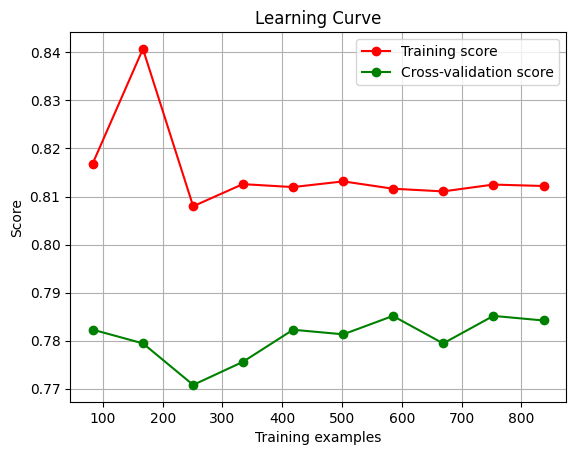

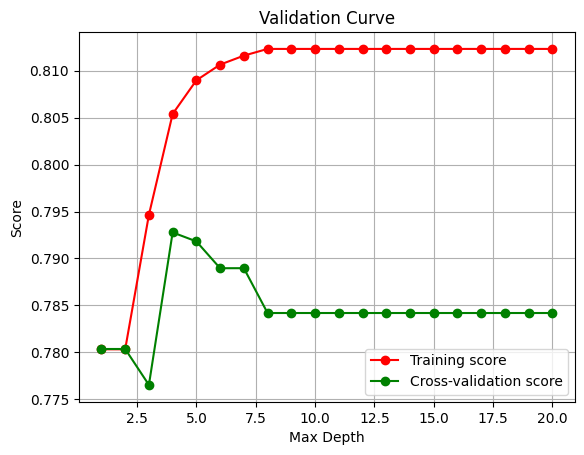

In [ ]:

# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_pred, output_dict=True)

# Create a DataFrame for precision, recall, and F1 score, excluding 'accuracy', 'macro avg', and 'weighted avg'
report_df = pd.DataFrame({
    'Precision': {key: value['precision'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'Recall': {key: value['recall'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'F1 Score': {key: value['f1-score'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']}
})

# Display the DataFrame as a table
print("\nCustom Classification Report:")
print(report_df)

# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(rf_model, X_train, y_train, n_jobs=1, train_sizes=np.linspace(0.1, 1.0, 10), cv=5)
plt.figure()
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

# Validation Curve
param_range = np.arange(1, 21)
train_scores, test_scores = validation_curve(rf_model, X_train, y_train, param_name="max_depth", param_range=param_range, cv=5)
plt.figure()
plt.plot(param_range, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(param_range, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Validation Curve")
plt.xlabel("Max Depth")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

### Random Forest changing Max depth
After analyzing the data obtained from the learning curve, we adjusted the depth to see if we could achieve better accuracy. The result obtained is not the same as that shown in the graph, as different subsets of data are used.

In [ ]:
# Define the hyperparameters for Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,       # Number of trees in the forest
    max_depth=20,           # Maximum depth of the tree
    min_samples_split=5,    # Minimum number of samples required to split an internal node
    min_samples_leaf=2,     # Minimum number of samples required to be at a leaf node
    bootstrap=True,         # Whether bootstrap samples are used when building trees
    random_state=42
)

# Train the Random Forest model on the training data
rf_model.fit(X_train, y_train)

# Predict the 'survived' column in the test dataset (Tdata)
X_test = Tdata.drop('survived', axis=1, errors='ignore')  # Drop 'survived' if present in Tdata
y_pred = rf_model.predict(X_test)

#Evaluate accuracy if you have the true 'survived' column in Tdata
y_test = Tdata['survived']
accuracy = accuracy_score(y_test, y_pred)
print(f'Model accuracy: {accuracy:.2f}')

Model accuracy: 0.78


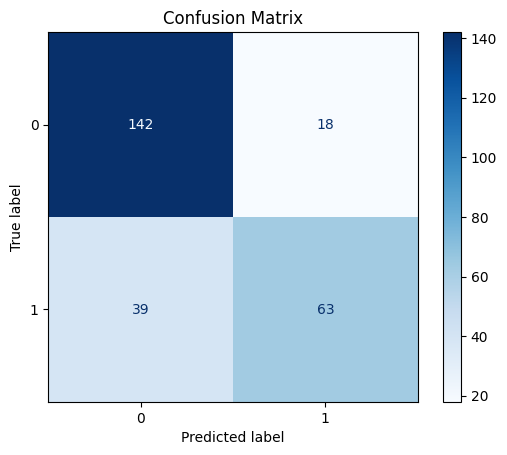


Custom Classification Report:
   Precision    Recall  F1 Score
0   0.784530  0.887500  0.832845
1   0.777778  0.617647  0.688525


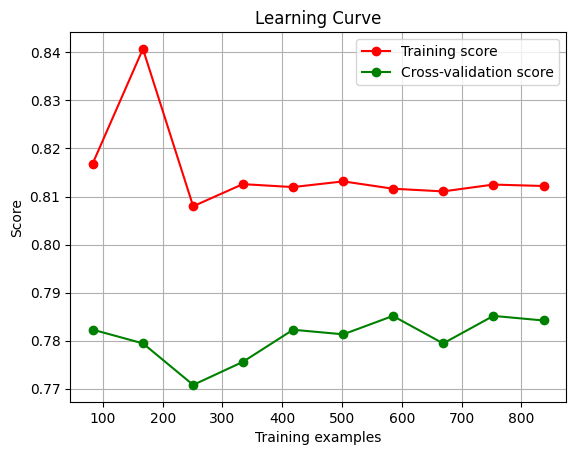

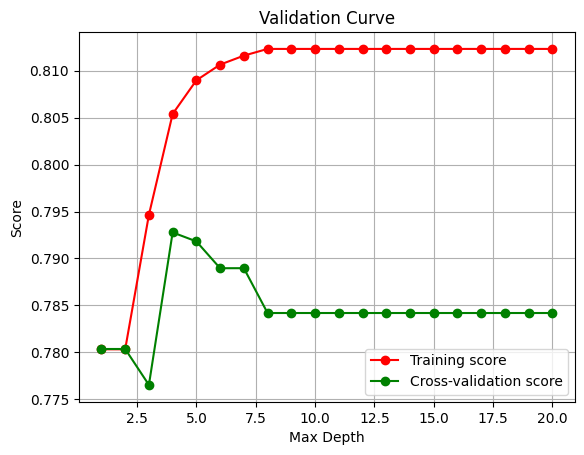

In [ ]:

# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_pred, output_dict=True)

# Create a DataFrame for precision, recall, and F1 score, excluding 'accuracy', 'macro avg', and 'weighted avg'
report_df = pd.DataFrame({
    'Precision': {key: value['precision'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'Recall': {key: value['recall'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'F1 Score': {key: value['f1-score'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']}
})

# Display the DataFrame as a table
print("\nCustom Classification Report:")
print(report_df)

# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(rf_model, X_train, y_train, n_jobs=1, train_sizes=np.linspace(0.1, 1.0, 10), cv=5)
plt.figure()
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

# Validation Curve
param_range = np.arange(1, 21)
train_scores, test_scores = validation_curve(rf_model, X_train, y_train, param_name="max_depth", param_range=param_range, cv=5)
plt.figure()
plt.plot(param_range, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(param_range, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Validation Curve")
plt.xlabel("Max Depth")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

### Random Forest with Grid search
Finally, we applied grid search, which will provide us with the optimal set of hyperparameters to achieve the best possible accuracy.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Set up the Random Forest model
model = RandomForestClassifier(random_state=42)

# Define the hyperparameter grid for Grid Search
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [10, 20, 30, None],
    'max_features': ['auto', 'sqrt', 'log2'],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

# Set up Grid Search
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,  # 5-fold cross-validation
    n_jobs=1,  # Use all available CPU cores
    verbose=0  # Silent mode
)

# Train the Grid Search
grid_search.fit(X_train, y_train)

# Print only the best hyperparameters and the best accuracy score
print("Best hyperparameters found:", grid_search.best_params_)
print("Best accuracy on the validation set:", grid_search.best_score_)

# Evaluate the model with the best hyperparameters on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy of the optimized model on the test set:", accuracy)

Best hyperparameters found: {'bootstrap': False, 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best accuracy on the validation set: 0.7880063795853269
Accuracy of the optimized model on the test set: 0.7786259541984732


In this part, we no longer generate the validation curve, as it doesn't make sense to consider hyperparameters when we have the optimal ones.

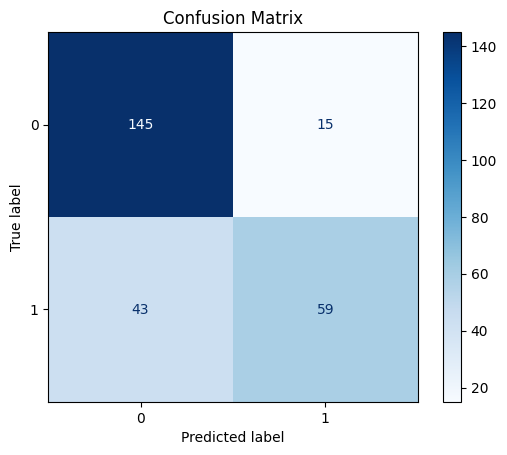


Custom Classification Report:
   Precision    Recall  F1 Score
0   0.771277  0.906250  0.833333
1   0.797297  0.578431  0.670455


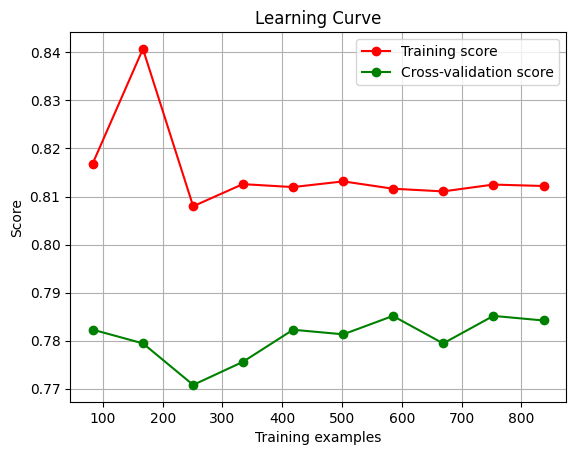

In [ ]:
# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_pred, output_dict=True)

# Create a DataFrame for precision, recall, and F1 score, excluding 'accuracy', 'macro avg', and 'weighted avg'
report_df = pd.DataFrame({
    'Precision': {key: value['precision'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'Recall': {key: value['recall'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'F1 Score': {key: value['f1-score'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']}
})

# Display the DataFrame as a table
print("\nCustom Classification Report:")
print(report_df)

# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(rf_model, X_train, y_train, n_jobs=1, train_sizes=np.linspace(0.1, 1.0, 10), cv=5)
plt.figure()
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

### Gradient Boosting

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Create and train the Gradient Boosting model
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("Model accuracy:", accuracy)



Model accuracy: 0.8053435114503816


### Cross Validation Gradient Boosting 
We applied cross-validation to the Gradient Boosting algorithm to see how it performs with new data.

In [ ]:
# Perform cross-validation
cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')  # 5-fold cross-validation

# Print cross-validation results
print(f'Cross-validation scores: {cv_scores}')
print(f'Average cross-validation accuracy: {cv_scores.mean():.2f}')



Cross-validation scores: [0.74285714 0.77619048 0.79904306 0.77990431 0.81818182]
Average cross-validation accuracy: 0.78


Now we create:
- Confusion matrix to see how the algorithm predicts each label. 

- Precision, recall, and F1 score: these metrics return the percentage of correct predictions among all those predicted as positive, the percentage of correct predictions among the actual positives, and the harmonic mean between precision and recall, respectively.

- Learning curve to observe how the algorithm behaves with different sample sizes, and we review the results using both training data and validation data while applying cross-validation.
 
- The validation curve functions similarly to the learning curve but focuses on a hyperparameter instead of the sample size; in this case, we use max depth, as it is one of the most significant hyperparameters.

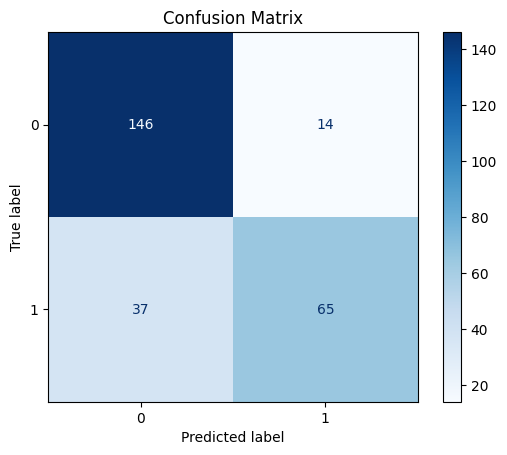


Custom Classification Report:
   Precision    Recall  F1 Score
0   0.797814  0.912500  0.851312
1   0.822785  0.637255  0.718232


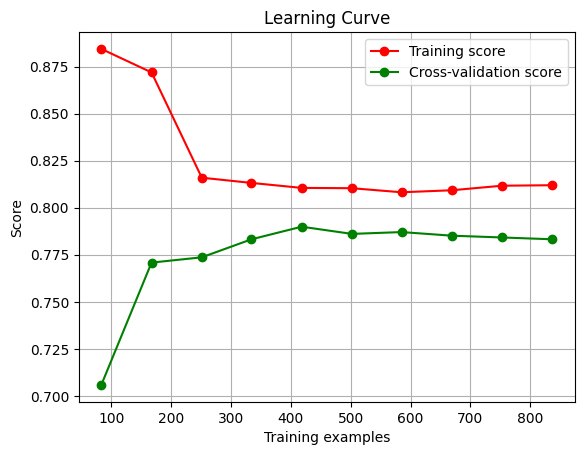

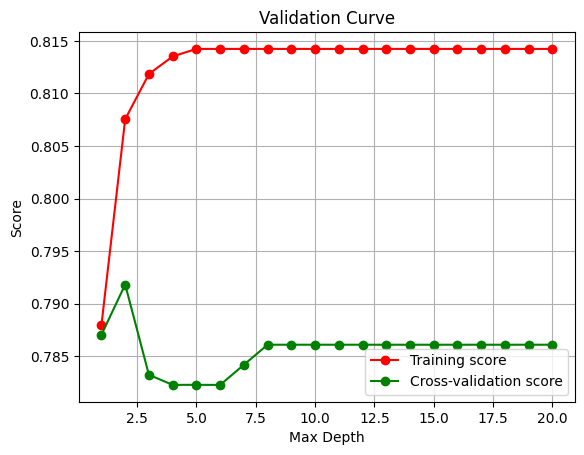

In [ ]:

# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_pred, output_dict=True)

# Create a DataFrame for precision, recall, and F1 score, excluding 'accuracy', 'macro avg', and 'weighted avg'
report_df = pd.DataFrame({
    'Precision': {key: value['precision'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'Recall': {key: value['recall'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'F1 Score': {key: value['f1-score'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']}
})

# Display the DataFrame as a table
print("\nCustom Classification Report:")
print(report_df)

# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(model, X_train, y_train, n_jobs=1, train_sizes=np.linspace(0.1, 1.0, 10), cv=5)
plt.figure()
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

# Validation Curve
param_range = np.arange(1, 21)
train_scores, test_scores = validation_curve(model, X_train, y_train, param_name="max_depth", param_range=param_range, cv=5)
plt.figure()
plt.plot(param_range, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(param_range, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Validation Curve")
plt.xlabel("Max Depth")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

### Gradient Boosting changing Max depth
After analyzing the data obtained from the learning curve, we adjusted the depth to see if we could achieve better accuracy. The result obtained is not the same as that shown in the graph, as different subsets of data are used.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Create and train the Gradient Boosting model
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print("Model accuracy:", accuracy)

Model accuracy: 0.7862595419847328


In [ ]:
# Perform cross-validation
cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')  # 5-fold cross-validation

# Print cross-validation results
print(f'Cross-validation scores: {cv_scores}')
print(f'Average cross-validation accuracy: {cv_scores.mean():.2f}')



Cross-validation scores: [0.75714286 0.78571429 0.80861244 0.78947368 0.81818182]
Average cross-validation accuracy: 0.79


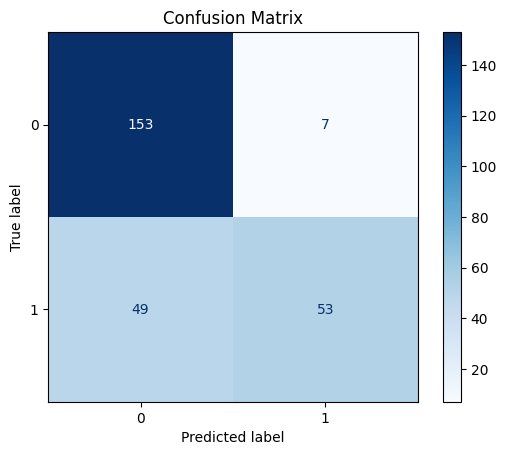


Custom Classification Report:
   Precision    Recall  F1 Score
0   0.757426  0.956250  0.845304
1   0.883333  0.519608  0.654321


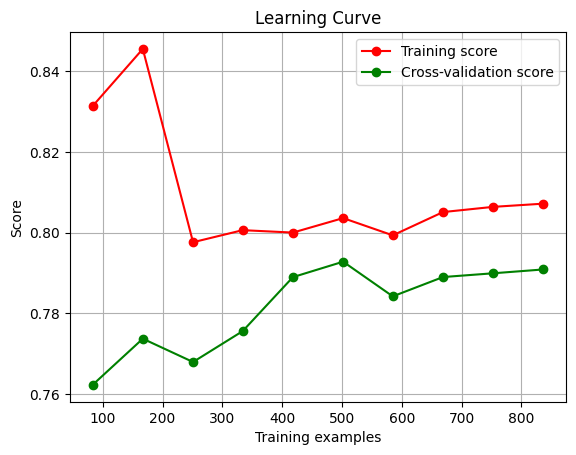

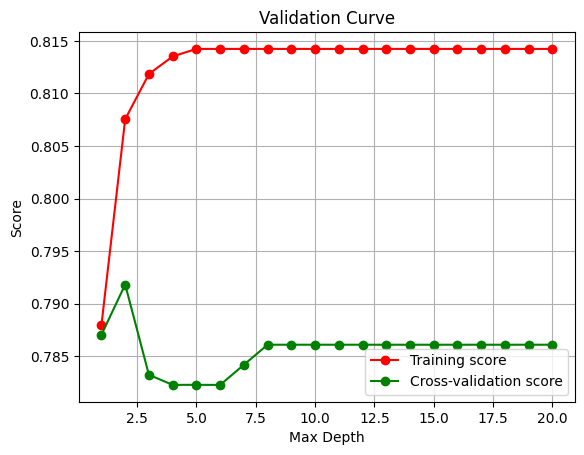

In [ ]:

# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_pred, output_dict=True)

# Create a DataFrame for precision, recall, and F1 score, excluding 'accuracy', 'macro avg', and 'weighted avg'
report_df = pd.DataFrame({
    'Precision': {key: value['precision'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'Recall': {key: value['recall'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'F1 Score': {key: value['f1-score'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']}
})

# Display the DataFrame as a table
print("\nCustom Classification Report:")
print(report_df)

# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(model, X_train, y_train, n_jobs=1, train_sizes=np.linspace(0.1, 1.0, 10), cv=5)
plt.figure()
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

# Validation Curve
param_range = np.arange(1, 21)
train_scores, test_scores = validation_curve(model, X_train, y_train, param_name="max_depth", param_range=param_range, cv=5)
plt.figure()
plt.plot(param_range, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(param_range, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Validation Curve")
plt.xlabel("Max Depth")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

### Gradient Boosting with Grid Search
Finally, we applied grid search, which will provide us with the optimal set of hyperparameters to achieve the best possible accuracy.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Set up the Gradient Boosting model
model = GradientBoostingClassifier(random_state=42)

# Define the hyperparameter grid for Grid Search
param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 1.0]
}

# Configure Grid Search without displaying all combinations
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,  # 5-fold cross-validation
    n_jobs=1,  # Use all available CPU cores
    verbose=0  # Silent mode
)

# Train the Grid Search
grid_search.fit(X_train, y_train)

# Print only the best parameters and best accuracy score
print("Best hyperparameters found:", grid_search.best_params_)
print("Best accuracy score on validation set:", grid_search.best_score_)

# Evaluate the model with the best hyperparameters on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Optimized model accuracy on the test set:", accuracy)

Best hyperparameters found: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 100, 'subsample': 0.8}
Best accuracy score on validation set: 0.8042469810890864
Optimized model accuracy on the test set: 0.7862595419847328


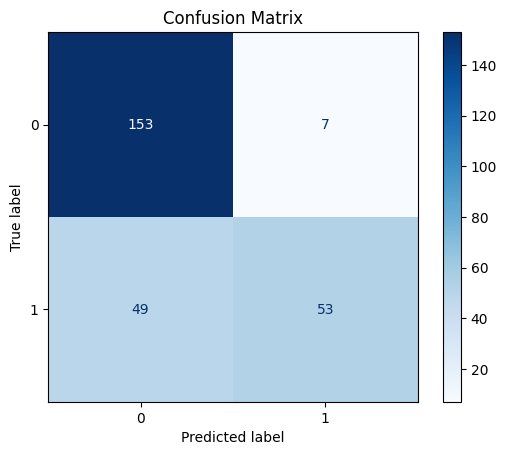


Custom Classification Report:
   Precision    Recall  F1 Score
0   0.757426  0.956250  0.845304
1   0.883333  0.519608  0.654321


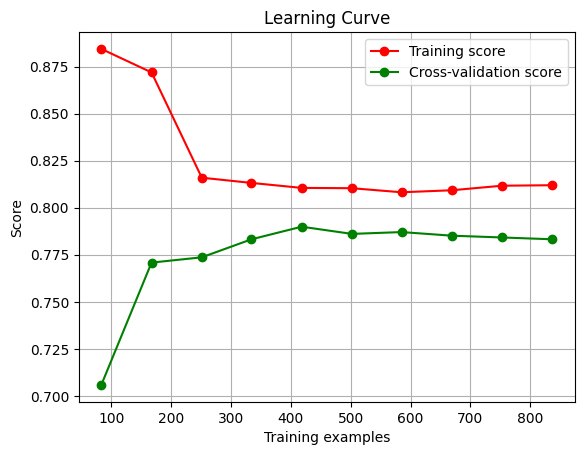

In [ ]:
# Confusion Matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_pred, output_dict=True)

# Create a DataFrame for precision, recall, and F1 score, excluding 'accuracy', 'macro avg', and 'weighted avg'
report_df = pd.DataFrame({
    'Precision': {key: value['precision'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'Recall': {key: value['recall'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']},
    'F1 Score': {key: value['f1-score'] for key, value in report.items() if key not in ['accuracy', 'macro avg', 'weighted avg']}
})

# Display the DataFrame as a table
print("\nCustom Classification Report:")
print(report_df)

# Learning Curve
train_sizes, train_scores, test_scores = learning_curve(model, X_train, y_train, n_jobs=1, train_sizes=np.linspace(0.1, 1.0, 10), cv=5)
plt.figure()
plt.plot(train_sizes, np.mean(train_scores, axis=1), 'o-', color="r", label="Training score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), 'o-', color="g", label="Cross-validation score")
plt.title("Learning Curve")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid()
plt.show()

In [ ]:
import pandas as pd

# Test-set accuracy of each configuration (values read from the cells above)
data_extended = {
    "Default":          [0.780, 0.805],
    "Cross-Validation": [0.78, 0.78],
    "Changing Depth":   [0.78, 0.786],
    "GridSearch":       [0.779, 0.786],
}
df_extended = pd.DataFrame(data_extended, index=["Random Forest", "Gradient Boosting"])
print("### Model Performance Comparison (leakage-free)")
print(df_extended.to_markdown(tablefmt="grid"))


### Model Performance Comparison
+-------------------+-----------+--------------------+------------------+--------------+
|                   |   Default |   Cross-Validation |   Changing Depth |   GridSearch |
+===================+===========+====================+==================+==============+
| Random Forest     |     0.96  |               0.98 |           0.96   |       0.9618 |
+-------------------+-----------+--------------------+------------------+--------------+
| Gradient Boosting |     0.958 |               0.98 |           0.9618 |       0.9618 |
+-------------------+-----------+--------------------+------------------+--------------+


# Report about the training of the model

We have chosen two models:

- Random Forest: We have chosen it mainly because it reduces overfitting and is robust against outliers. With a long list of data like this, these problems are present. Among the issues, it is noteworthy that it can have a high computational cost.

- Gradient Boosting: We have taken this choice considering its high accuracy in prediction and its ability to capture complex patterns, assuming the risk of potential overfitting and its high computational cost.

In each case, we followed a similar approach. First, we trained the model with default parameters, taking into account the size of the dataset. After this, we obtained the accuracy percentage. Then we performed cross-validation, and in both cases, we obtained very similar averages (around 0.78-0.79). This may be due to the robustness of the model, the characteristics of the data, or the tuning of the hyperparameters.

The next step has been to use the confusion matrix and the F1, recall, and precision metrics to better visualize the predictions of our algorithms. We have also generated validation curve graphs, where we see how the model's accuracy varies with changes in an important hyperparameter, such as depth. Additionally, we created learning curves that allow us to observe how accuracy evolves based on the sample size for both training data and validation, where we also performed cross-validation. In both graphs, for all cases, we observe instances of underfitting for low values and overfitting for high values ,sample size for the learning curve and depth for the validation curve. With the validation curve, we can vary the hyperparameter depth to achieve greater accuracy. We see that the most significant change is reflected in Gradient Boosting.

Finally, we applied grid search to all the algorithms, which will give us the combination of hyperparameters that provides the best accuracy.

As a conclusion, once the leaking variable `boat` is removed, accuracy settles at roughly 0.78-0.81 for both models, whether using default hyperparameters, manually modifying some, or optimizing them through grid search. Gradient Boosting with default parameters scored highest on the test set (0.805), but the differences between configurations are within the spread of the cross-validation folds (about ±0.03), so no configuration is clearly superior. For this dataset size the simplest approach is therefore sufficient, since grid search and validation curves have a higher computational cost without a significant gain.

**Why the numbers are lower than in an earlier version.** An earlier version of this analysis kept `boat` as a predictor and reported 96-98 % accuracy. That figure was inflated by data leakage and is not a valid estimate of predictive performance.
